# Titanic Passenger Survival Analysis — Statistics & Trends

This notebook reproduces the three visual analyses shown in the supplied assignment:
1. Passenger Age vs Fare by Survival Status
2. Survival Rate by Class and Sex
3. Age Distribution by Class and Survival

**Dataset:** `titanic_passenger_dataset.csv` (891 passenger records, 15 columns).  
Keep the CSV in the same folder as this notebook before running it.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5.5)
plt.rcParams["figure.dpi"] = 110

df = pd.read_csv("titanic_passenger_dataset.csv")
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (891, 15)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,FamilySize,IsAlone,AgeGroup
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,2,0,Young Adult
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,2,0,Adult
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,1,1,Young Adult
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,2,0,Adult
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,1,1,Adult


## 1. Data overview and preparation

In [2]:
print("Rows and columns:", df.shape)
print("\\nColumn data types:")
print(df.dtypes)
print("\\nMissing values:")
display(df.isna().sum().to_frame("Missing values"))
print("\\nSurvival counts (0 = Did not survive, 1 = Survived):")
display(df["Survived"].value_counts().sort_index())

Rows and columns: (891, 15)
\nColumn data types:
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
FamilySize       int64
IsAlone          int64
AgeGroup        object
dtype: object
\nMissing values:


,Missing values
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


\nSurvival counts (0 = Did not survive, 1 = Survived):


Survived
0    549
1    342
Name: count, dtype: int64

## 2. Figure 1 — Passenger Age vs Fare by Survival Status

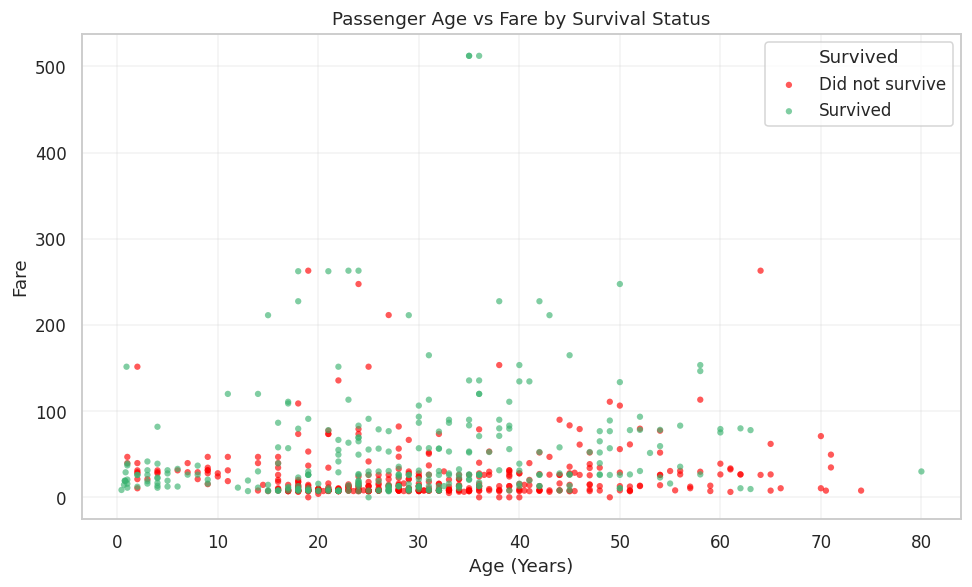

Pearson correlation between age and fare: 0.096


In [3]:
plot_df = df.dropna(subset=["Age", "Fare", "Survived"]).copy()
colors = {0: "red", 1: "mediumseagreen"}
labels = {0: "Did not survive", 1: "Survived"}

fig, ax = plt.subplots(figsize=(9, 5.5))
for status in [0, 1]:
    part = plot_df[plot_df["Survived"] == status]
    ax.scatter(part["Age"], part["Fare"], s=17, alpha=0.65,
               c=colors[status], label=labels[status], edgecolors="none")
ax.set_title("Passenger Age vs Fare by Survival Status")
ax.set_xlabel("Age (Years)")
ax.set_ylabel("Fare")
ax.legend(title="Survived")
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

print("Pearson correlation between age and fare:",
      round(plot_df["Age"].corr(plot_df["Fare"]), 3))

## 3. Figure 2 — Survival Rate by Class and Sex

Sex,female,male
Pclass,,
1,96.8,36.9
2,92.1,15.7
3,50.0,13.5


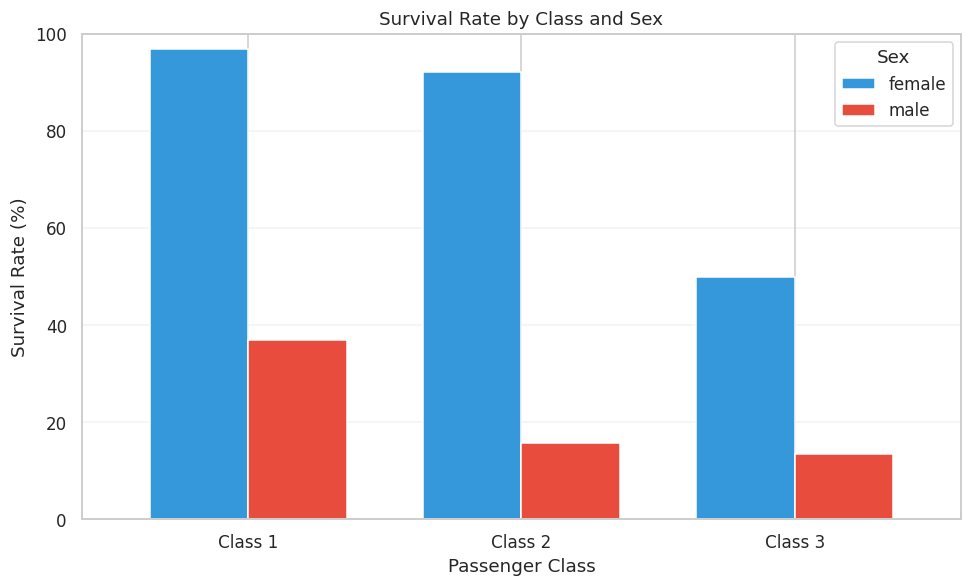

In [4]:
survival_table = (
    df.groupby(["Pclass", "Sex"], observed=True)["Survived"]
      .mean().mul(100).unstack()
)
display(survival_table.round(1))

ax = survival_table.plot(kind="bar", figsize=(9, 5.5),
                         color=["#3498db", "#e74c3c"], width=0.72)
ax.set_title("Survival Rate by Class and Sex")
ax.set_xlabel("Passenger Class")
ax.set_ylabel("Survival Rate (%)")
ax.set_xticklabels(["Class 1", "Class 2", "Class 3"], rotation=0)
ax.set_ylim(0, 100)
ax.legend(title="Sex")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 4. Figure 3 — Age Distribution by Class and Survival

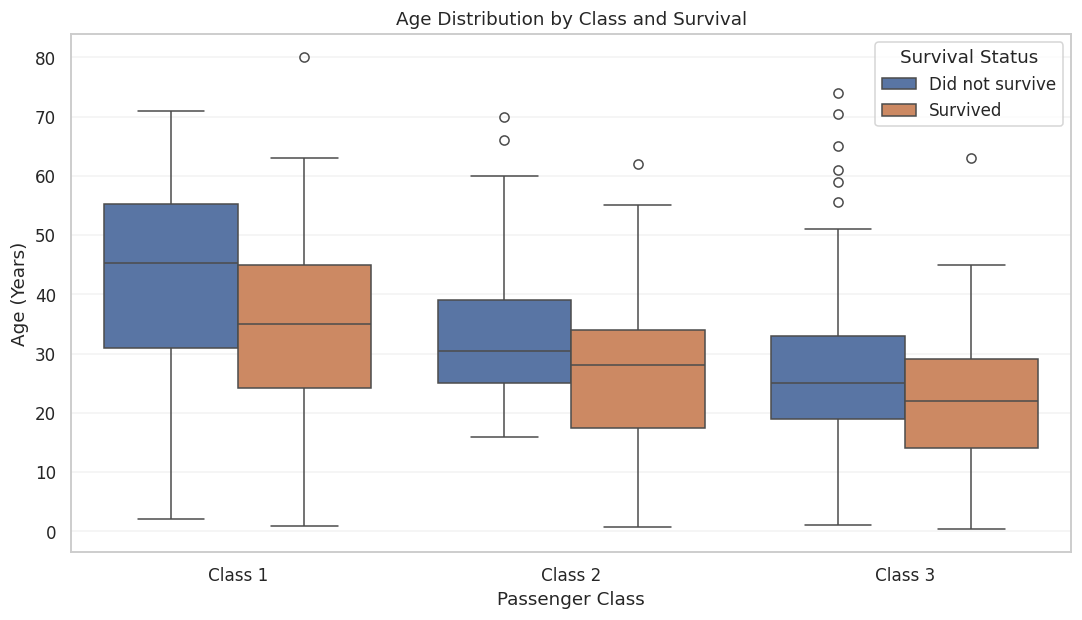

In [5]:
age_df = df.dropna(subset=["Age"]).copy()
age_df["Passenger Class"] = age_df["Pclass"].map(
    {1: "Class 1", 2: "Class 2", 3: "Class 3"}
)
age_df["Survival Status"] = age_df["Survived"].map(
    {0: "Did not survive", 1: "Survived"}
)

fig, ax = plt.subplots(figsize=(10, 5.8))
sns.boxplot(data=age_df, x="Passenger Class", y="Age",
            hue="Survival Status", order=["Class 1", "Class 2", "Class 3"],
            hue_order=["Did not survive", "Survived"], ax=ax)
ax.set_title("Age Distribution by Class and Survival")
ax.set_xlabel("Passenger Class")
ax.set_ylabel("Age (Years)")
ax.legend(title="Survival Status")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 5. Key summary statistics

In [6]:
summary = df.groupby("Pclass").agg(
    Passengers=("PassengerId", "count"),
    Average_Age=("Age", "mean"),
    Average_Fare=("Fare", "mean"),
    Survival_Rate=("Survived", "mean")
)
summary["Survival_Rate"] = (summary["Survival_Rate"] * 100).round(1)
display(summary.round(2))

print("Overall survival rate: {:.1f}%".format(df["Survived"].mean() * 100))
print("Dataset contains {} passenger records and {} columns.".format(*df.shape))

,Passengers,Average_Age,Average_Fare,Survival_Rate
Pclass,,,,
1,216,38.23,84.15,63.0
2,184,29.88,20.66,47.3
3,491,25.14,13.68,24.2


Overall survival rate: 38.4%
Dataset contains 891 passenger records and 15 columns.


## Notes
- `Survived`: 0 = did not survive; 1 = survived.
- `Pclass`: 1 = first class, 2 = second class, 3 = third class.
- The dataset contains missing values for some passenger ages, cabins and embarkation points. The plots that require age exclude rows with missing age; the original dataset is not modified.
- The three additional columns are derived for analysis: `FamilySize`, `IsAlone`, and `AgeGroup`.
- Results may differ slightly from values written in the sample report if its author used a different version or calculation method. The charts here are generated directly from the included CSV.